# Classification of Legal Text: experiments
    **Team 9:** Sai Sathvik Gullipalli (PES2UG24CS430) and Priyanka Mallikarjuna Reddy (PES2UG24CS378).

    This notebook reproduces our workflow on the original textacy Supreme Court corpus.
    It trains TF-IDF, LDA, and Doc2Vec classifiers, selects configurations on validation
    macro-F1, and evaluates the frozen models on a held-out test partition.

    **Local:** install `requirements.txt` in the project's virtual environment and select its kernel.
    **Colab:** upload this notebook, run setup, then upload `team9-project.zip` when prompted.
    Use a Python 3.11 or 3.12 CPU runtime. No paid service or GPU is needed.
    A saved run loads its results without evaluating the test set again.

In [1]:
import os, sys, json, subprocess, zipfile
from pathlib import Path

try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = False
if IS_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

def extract_trusted_zip(path, target):
    target = Path(target).resolve()
    with zipfile.ZipFile(path) as z:
        for member in z.infolist():
            if not (target / member.filename).resolve().is_relative_to(target):
                raise ValueError("Archive contains an unsafe path")
        z.extractall(target)

def find_project():
    for parent in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [parent, parent / "legal_text_classification"]:
            if (candidate / "src" / "legal_text").is_dir():
                return candidate.resolve()
    return None

ROOT = find_project()
if ROOT is None and IS_COLAB:
    print("Upload team9-project.zip from the private GitHub release.")
    from google.colab import files
    for filename in files.upload():
        if filename.endswith(".zip"):
            extract_trusted_zip(filename, Path.cwd())
    ROOT = find_project()
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the extracted legal_text_classification project.")
os.chdir(ROOT)
if IS_COLAB:
    # Run this setup cell before importing NumPy/scikit-learn/gensim. If those
    # libraries were previously imported, restart the session after installation.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".build" / "matplotlib"))
print("Project:", ROOT)
print("Python:", sys.version.split()[0])

Project: /Users/admin/Documents/ChatGPT/meth/legal_text_classification
Python: 3.11.9


## Train or load an existing run
    Feature learning uses training opinions only. The subprocess starts with fixed
    hashing and thread settings for reproducibility. Training can take tens of minutes
    on a CPU, depending on hardware. Use the saved demo bundle during the review.

In [2]:
metrics_path = ROOT / "results" / "metrics.json"
if metrics_path.exists():
    print("Loading completed results. No models are retrained and the test set is not reevaluated.")
else:
    env = dict(os.environ, PYTHONHASHSEED="42", OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
    env["PYTHONPATH"] = str(ROOT / "src")
    subprocess.run([sys.executable, "-m", "legal_text.train", "--project-root", str(ROOT)], env=env, check=True)

Loading completed results. No models are retrained and the test set is not reevaluated.


## Dataset, cleaning, and fixed partitions

In [3]:
import pandas as pd
from IPython.display import display, Image
summary = json.loads((ROOT / "results/dataset_summary.json").read_text())
provenance = json.loads((ROOT / "results/provenance.json").read_text())
print("Dataset SHA256:", provenance["sha256"])
print("Source:", provenance["source_page"])
print("Raw records:", summary["raw_records"], "Retained:", summary["retained_records"])
print("Excluded rare categories:", summary["excluded_rare_categories"])
display(pd.DataFrame({n: v["class_counts"] for n, v in summary["splits"].items()}).fillna(0).astype(int))
manifest = pd.read_csv(ROOT / "results/split_manifest.csv", keep_default_na=False)
assert manifest.groupby("group")["split"].nunique().max() == 1
assert manifest.groupby("text_hash")["split"].nunique().max() == 1
print("Verified: case groups and identical texts never cross partitions.")

Dataset SHA256: 2909fc637b44326b7f588371828f6446883dc9c66cf31f6a5805a50248fbb0f4
Source: https://github.com/bdewilde/textacy-data/releases/tag/supreme_court_py3_v1.0
Raw records: 8419 Retained: 8373
Excluded rare categories: {'14': 1}


,train,validation,test
Economic Activity,998,322,345
Civil Rights,779,283,292
Judicial Power,661,240,237
Unions,225,59,61
Criminal Procedure,1172,375,375
Federal Taxation,161,75,68
First Amendment,399,134,125
Privacy,77,15,18
Interstate Relations,38,11,9
Due Process,210,65,60


Verified: case groups and identical texts never cross partitions.


## Validation selection
Macro-F1 gives each category equal weight. Test scores do not participate in this choice.

In [4]:
candidates = pd.read_csv(ROOT / "results/validation_candidates.csv")
display(candidates[["model", "topics", "C", "accuracy", "macro_f1", "weighted_f1"]])
selection = json.loads((ROOT / "results/selection.json").read_text())
print("Validation-selected winner:", selection["winner"])
print("Tie-breaks:", selection["selection_metric"])

,model,topics,C,accuracy,macro_f1,weighted_f1
0,tfidf,NaN,0.1,0.599403,0.266706,0.533078
1,tfidf,NaN,1.0,0.764179,0.559716,0.750648
2,tfidf,NaN,10.0,0.800597,0.681670,0.796143
3,lda,20.0,0.1,0.602388,0.323744,0.559810
4,lda,20.0,1.0,0.629254,0.371605,0.597969
5,lda,20.0,10.0,0.637612,0.401088,0.609206
6,lda,40.0,0.1,0.626269,0.346252,0.586809
7,lda,40.0,1.0,0.656716,0.402549,0.625777
8,lda,40.0,10.0,0.675224,0.480588,0.657753
9,doc2vec,NaN,0.1,0.743881,0.617141,0.736028


Validation-selected winner: tfidf
Tie-breaks: validation macro-F1, accuracy, then end-to-end inference latency


## Frozen test results

,accuracy,macro_f1,weighted_f1,test_ms_per_document,train_seconds
majority,0.223881,0.028143,0.081908,NaN,NaN
tfidf,0.818507,0.718577,0.814364,7.142138,146.682140
lda,0.687761,0.522102,0.677283,5.103456,84.032056
doc2vec,0.734925,0.642808,0.729550,105.072569,1568.336844


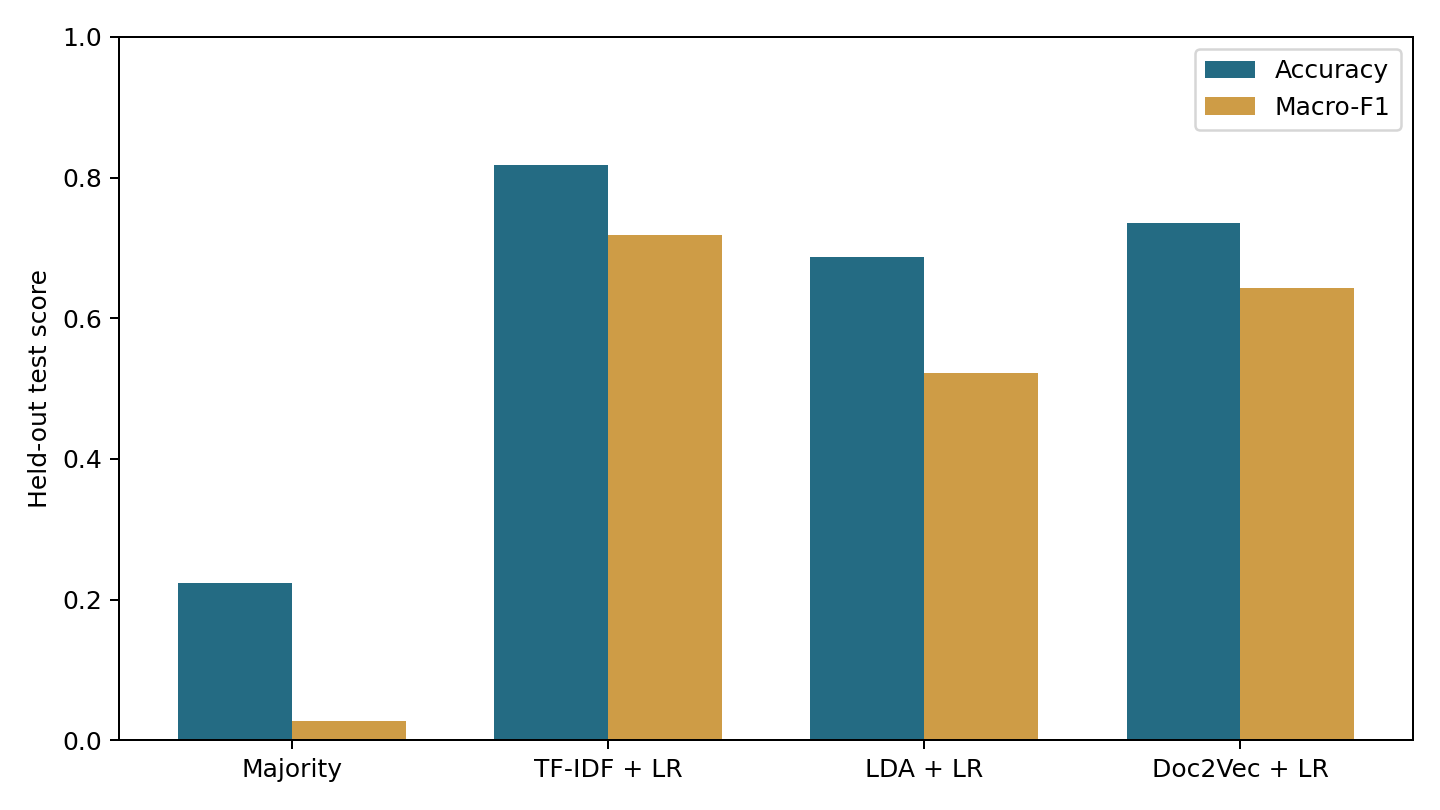

tfidf


,category,precision,recall,f1-score,support
0,Criminal Procedure,0.845783,0.936000,0.888608,375.0
1,Civil Rights,0.843416,0.811644,0.827225,292.0
2,First Amendment,0.814815,0.880000,0.846154,125.0
3,Due Process,0.789474,0.500000,0.612245,60.0
4,Privacy,0.916667,0.611111,0.733333,18.0
5,Attorneys,0.857143,0.571429,0.685714,21.0
6,Unions,0.786885,0.786885,0.786885,61.0
7,Economic Activity,0.790698,0.886957,0.836066,345.0
8,Judicial Power,0.759259,0.691983,0.724062,237.0
9,Federalism,0.745455,0.672131,0.706897,61.0


lda


,category,precision,recall,f1-score,support
0,Criminal Procedure,0.797500,0.850667,0.823226,375.0
1,Civil Rights,0.676471,0.630137,0.652482,292.0
2,First Amendment,0.768657,0.824000,0.795367,125.0
3,Due Process,0.789474,0.250000,0.379747,60.0
4,Privacy,0.666667,0.666667,0.666667,18.0
5,Attorneys,0.538462,0.333333,0.411765,21.0
6,Unions,0.704918,0.704918,0.704918,61.0
7,Economic Activity,0.693267,0.805797,0.745308,345.0
8,Judicial Power,0.472119,0.535865,0.501976,237.0
9,Federalism,0.393939,0.213115,0.276596,61.0


doc2vec


,category,precision,recall,f1-score,support
0,Criminal Procedure,0.815348,0.906667,0.858586,375.0
1,Civil Rights,0.756198,0.626712,0.685393,292.0
2,First Amendment,0.706667,0.848000,0.770909,125.0
3,Due Process,0.615385,0.400000,0.484848,60.0
4,Privacy,0.700000,0.777778,0.736842,18.0
5,Attorneys,0.812500,0.619048,0.702703,21.0
6,Unions,0.746032,0.770492,0.758065,61.0
7,Economic Activity,0.728232,0.800000,0.762431,345.0
8,Judicial Power,0.588745,0.573840,0.581197,237.0
9,Federalism,0.589286,0.540984,0.564103,61.0


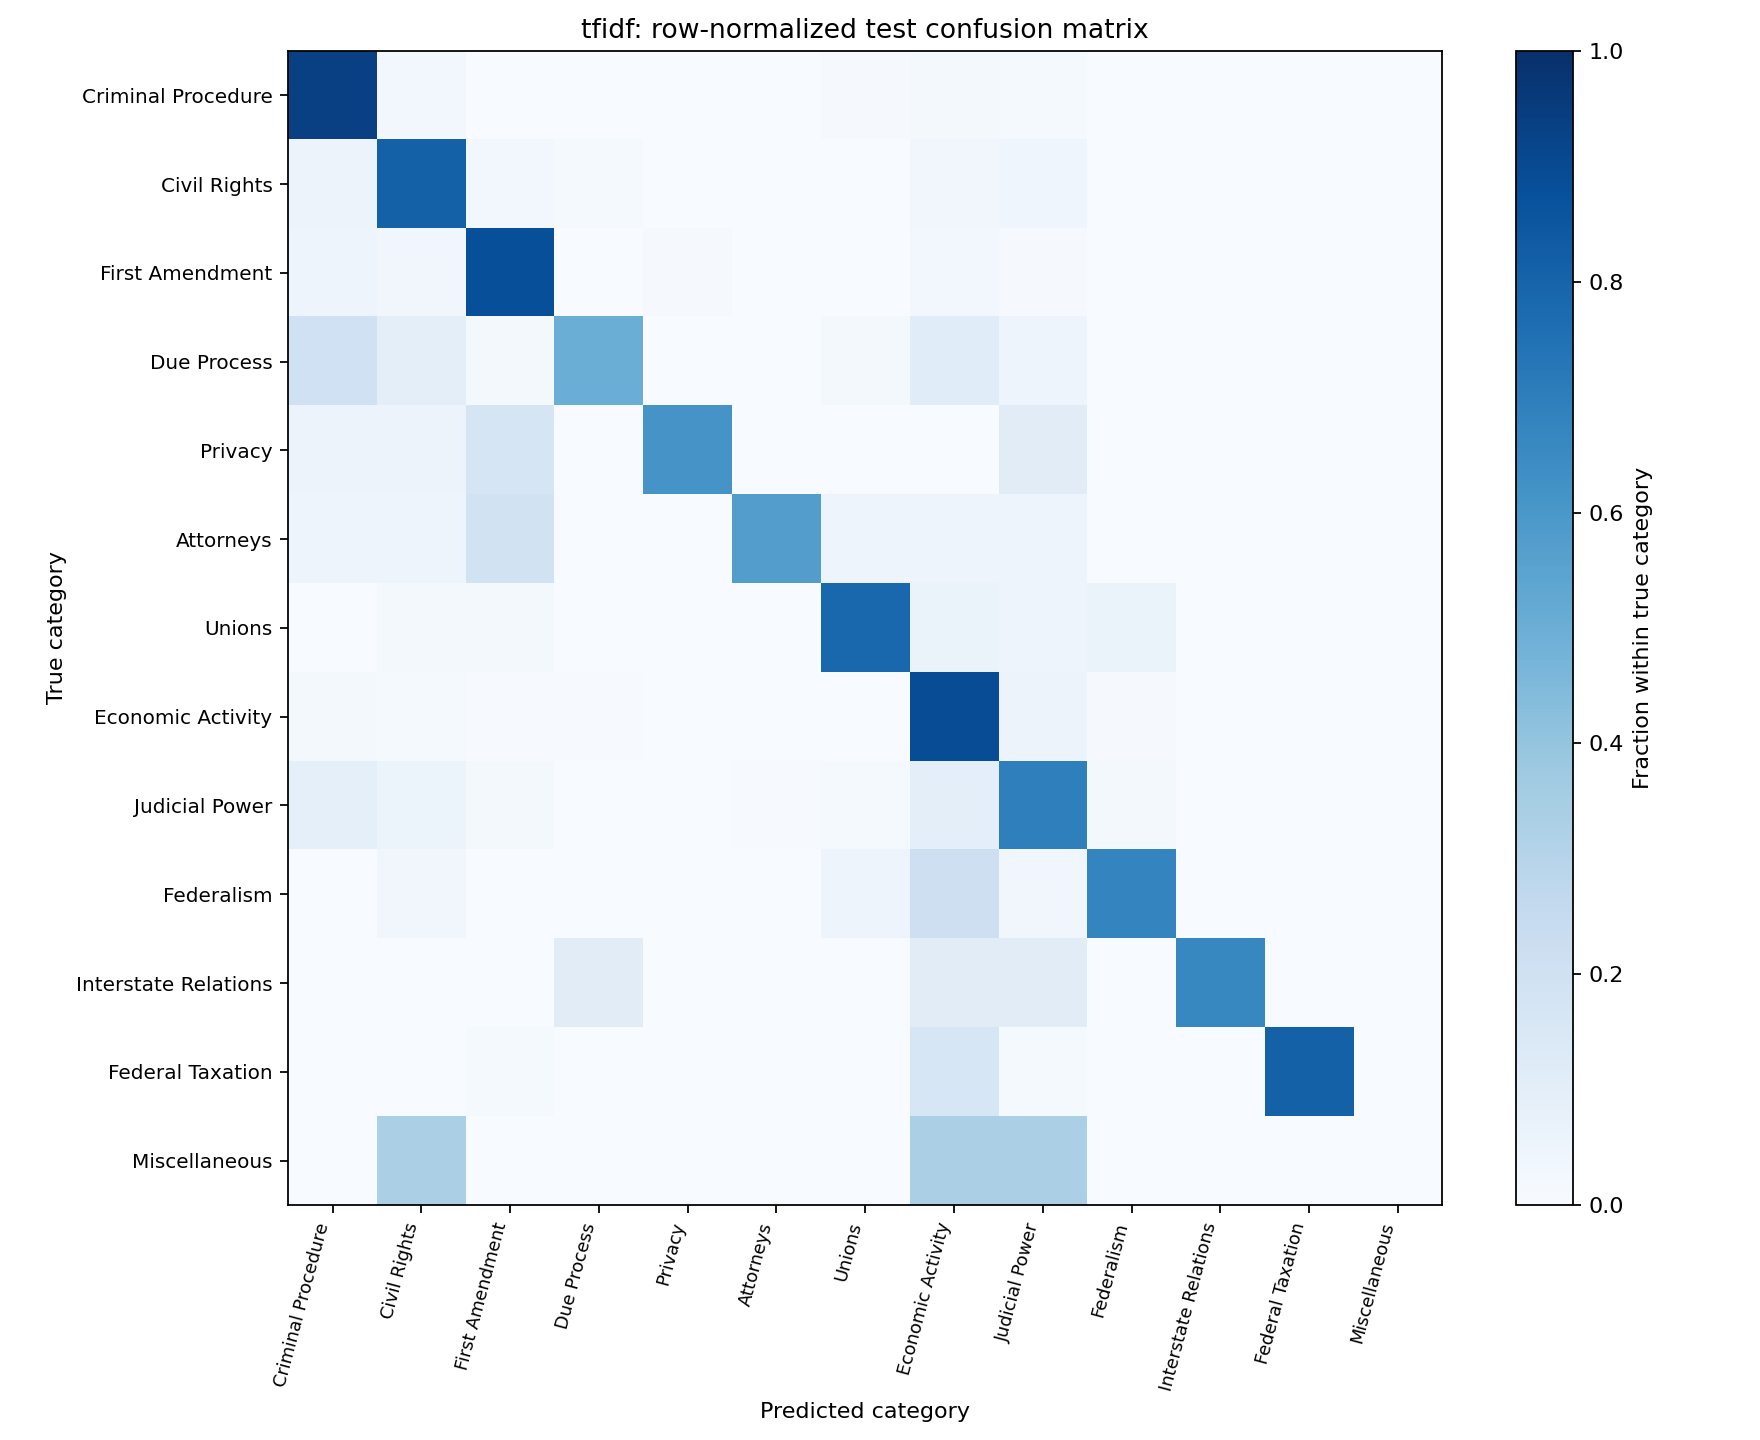

In [5]:
metrics = json.loads(metrics_path.read_text())
display(pd.DataFrame(metrics).T)
display(Image(filename=str(ROOT / "results/model_comparison.png")))
for name in ("tfidf", "lda", "doc2vec"):
    print(name)
    display(pd.read_csv(ROOT / f"results/{name}_per_category.csv"))
display(Image(filename=str(ROOT / f"results/{selection['winner']}_confusion_matrix.png")))

## Interpretation
    LDA uses count features because its generative model describes word counts.
    This differs from the reference report's stated TF-IDF input. Doc2Vec can discover
    similarity between opinions, but that similarity does not establish legal authority.
    Random grouped splits measure performance on this historical corpus, not generalization
    to future cases. Small categories and possible source metadata mismatches limit conclusions.

    See `docs/viva.md` for explanations and `results/` for all exported evidence.
    Open `02_live_demo.ipynb` for interactive inference without retraining.

In [6]:
if IS_COLAB:
    import shutil
    archive = shutil.make_archive(str(ROOT / "team9-model-bundle"), "zip", root_dir=ROOT, base_dir="artifacts")
    from google.colab import files
    files.download(archive)
else:
    print("Saved artifacts:", ROOT / "artifacts")

Saved artifacts: /Users/admin/Documents/ChatGPT/meth/legal_text_classification/artifacts
